#### About project and dataset
In this project, I am using the "Women's E-Commerce Clothing Reviews" dataset, which has real, anonymized commercial reviews. I downloaded the dataset from Kaggle: https://www.kaggle.com/datasets/nicapotato/womens-ecommerce-clothing-reviews/data.

The dataset comprises 23,486 individual customer entries, each represented by ten distinct feature variables. Every observation captures a unique review, pairing the shopper's raw text with specific metadata, such as age and product categories, to provide a comprehensive view of the customer experience.

**Objctive**: Online retailers receive thousands of customer reviews, and analyzing these reviews manually is inefficient and time consuming. Retailers need some automated process that can quickly understand customer sentiment and predict product performance.

The core objective is to transform these unstructured text reviews into actionable business insights. By doing sentiment analysis, I am predicting what reviews lead a customer to recommend a product and product ratings. This process involves cleaning the text, engineering features like review length and sentiment, and identifying demographic trends within the shopping base.

**1. Predicting Product Recommendation** : I want to predict whether a customer will recommend a product (Recommended IND) based on review text and customer metadata, so that company may proactively 
- Identify high-risk products
- Understand key drivers of dissatisfaction
- Make data-driven decisions to improve product quality
- Improve customer satisfaction and engagement

**This is the primary objective, a supervised sentiment classficaiton model.**

**2. Predicting Product Ratings (Regression)** I will also train a model to predict product ratings from review text and customer features. In some cases, the review text may raise concerns even when the rating remains above average. This insight enables the company to improve product quality, customer service, and recommendation strategies, thereby enhancing overall customer satisfaction and sales performance.

### Dataset

"Womens Clothing E-Commerce Reviews" has the following features and target label.
#### Attributes
**Clothing ID**: Integer Categorical variable that refers to the specific piece being reviewed.

**Age**: Positive Integer variable of the reviewer's age.Age: Positive Integer variable of the reviewer's age.

**Title**: String variable for the title of the review.

**Review Text**: String variable for the review body.

**Rating**: Positive Ordinal Integer variable for the product score granted by the customer from 1 Worst, to 5 Best.

**Recommended IND**: Binary variable stating where the customer recommends the product, where 1 is recommended, 0 is not recommended.

**Positive Feedback Count**: Positive Integer documenting the number of other customers who found this review positive.

**Division Name**: Categorical name of the product high-level division.

**Department Name**: Categorical name of the product department.

**Class Name**: Categorical name of the product class.

In [1]:
# import libraries
import pandas as pd
import numpy as np
import seaborn as sns
import logging
import matplotlib.pyplot as plt
import string

from sklearn import set_config
set_config(display = 'text') 

pd.set_option('display.max_columns',50) # setting up the dataframe display columns
pd.set_option('display.max_colwidth', 100) # setting up column width 100

### Loading data file

I downloaded and copied "Womens Clothing E-Commerce Reviews.csv" file from Kaggle.

In [2]:
file_ecom= 'Womens Clothing E-Commerce Reviews.csv' # file is saved in current directory.

# Catch any exception reading file
try:
    df_ecom = pd.read_csv(f"{file_ecom}", sep = ",")
except FileNotFoundError as e: # if file is not not found. 
    logging.error(f"{file_ecom} is not found, please check the file path or name.\n{e}")

### EDA: Exploratory Data Analysis

Understanding data, data cleaning, calculating descriptive statistics, and visualizing distributions for modeling.

In [3]:
df_ecom.head()

,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,0,767,33,NaN,Absolutely wonderful - silky and sexy and comfortable,4,1,0,Initmates,Intimate,Intimates
1,1,1080,34,NaN,"Love this dress! it's sooo pretty. i happened to find it in a store, and i'm glad i did bc i n...",5,1,4,General,Dresses,Dresses
2,2,1077,60,Some major design flaws,I had such high hopes for this dress and really wanted it to work for me. i initially ordered th...,3,0,0,General,Dresses,Dresses
3,3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, flirty, and fabulous! every time i wear it, i get no...",5,1,0,General Petite,Bottoms,Pants
4,4,847,47,Flattering shirt,This shirt is very flattering to all due to the adjustable front tie. it is the perfect length t...,5,1,6,General,Tops,Blouses


"Unnamed: 0" columns usually appear because the original CSV file was saved with an index, and when pandas loads it, it treats that old index as a new data column.

In [4]:
# Remove the "Unnamed" column
df_eda = df_ecom.copy()
df_eda = df_eda.drop(columns=['Unnamed: 0'])

In [5]:
print("Descriptive statistics:")
df_eda.describe()

Descriptive statistics:


,Clothing ID,Age,Rating,Recommended IND,Positive Feedback Count
count,23486.000000,23486.000000,23486.000000,23486.000000,23486.000000
mean,918.118709,43.198544,4.196032,0.822362,2.535936
std,203.298980,12.279544,1.110031,0.382216,5.702202
min,0.000000,18.000000,1.000000,0.000000,0.000000
25%,861.000000,34.000000,4.000000,1.000000,0.000000
50%,936.000000,41.000000,5.000000,1.000000,1.000000
75%,1078.000000,52.000000,5.000000,1.000000,3.000000
max,1205.000000,99.000000,5.000000,1.000000,122.000000


Most customers are aged 34 to 52 and generally provide high ratings. 

Age might have an outlier, that I deal in data preparation task.

#### Age distrrbution

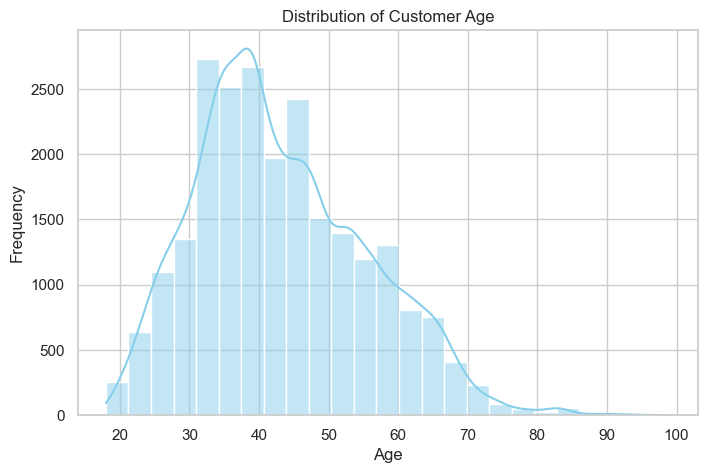

In [6]:
sns.set_theme(style="whitegrid")

# Distribution of Age
plt.figure(figsize=(8, 5))
sns.histplot(df_eda['Age'], bins=25, kde=True, color='skyblue')
plt.title('Distribution of Customer Age')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()

The Age variable shows that the primary customer demographic is middle-aged, which could be critical for the business problem. Since preferences for style and fit often change with life stages.

#### Rating distribution

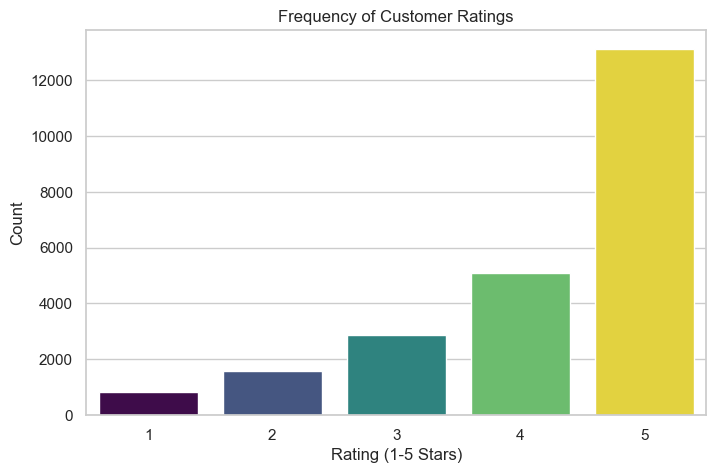

In [7]:
plt.figure(figsize=(8, 5))
sns.countplot(x='Rating', data=df_eda, hue='Rating', palette='viridis', legend=False)

plt.title('Frequency of Customer Ratings')
plt.xlabel('Rating (1-5 Stars)')
plt.ylabel('Count')
plt.show()

The massive peak is at the 5-star level, It means that majority of customers have a positive reviews and are extremely satisfied with their purchase. The number of 5-star ratings is nearly double that of 4-star ratings and far exceeds all other categories combined.

#### Recommendation Rate by Department

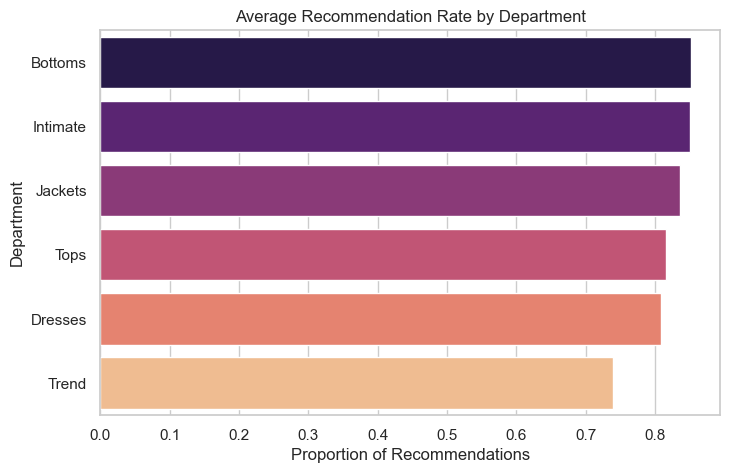

In [8]:
plt.figure(figsize=(8, 5))

dept_rec = df_eda.groupby('Department Name')['Recommended IND'].mean().sort_values(ascending=False).reset_index()

sns.barplot(x='Recommended IND', y='Department Name', data=dept_rec, palette='magma', 
            hue='Department Name', legend=False)

plt.title('Average Recommendation Rate by Department')
plt.xlabel('Proportion of Recommendations')
plt.ylabel('Department')
plt.show()

The graph shows that recommendation rates vary across departments, identifying which categories are top performers and which may have quality issues.

#### Age vs Recommended IND (Box Plot)

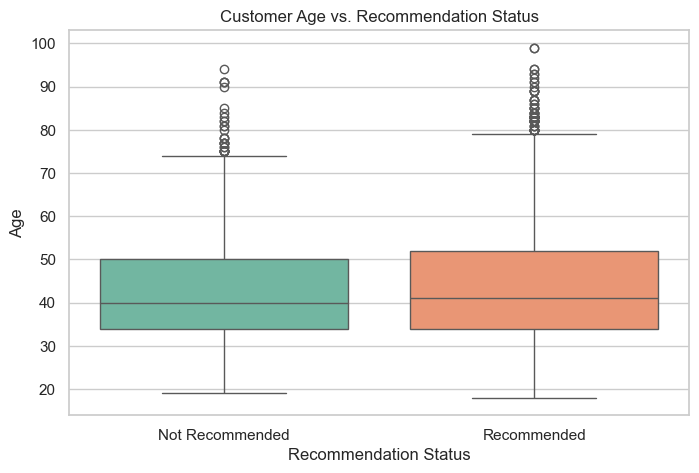

In [9]:
plt.figure(figsize=(8, 5))
sns.boxplot(x='Recommended IND', y='Age', data=df_eda, hue='Recommended IND', palette='Set2', legend=False)

plt.title('Customer Age vs. Recommendation Status')
plt.xticks([0, 1], ['Not Recommended', 'Recommended'])
plt.xlabel('Recommendation Status')
plt.ylabel('Age')
plt.show()

This box plot shows that the age distribution is almost identical for both groups, meaning age is not a primary factor in whether a customer recommends a product. It confirms that customer satisfaction is consistent across all generations,

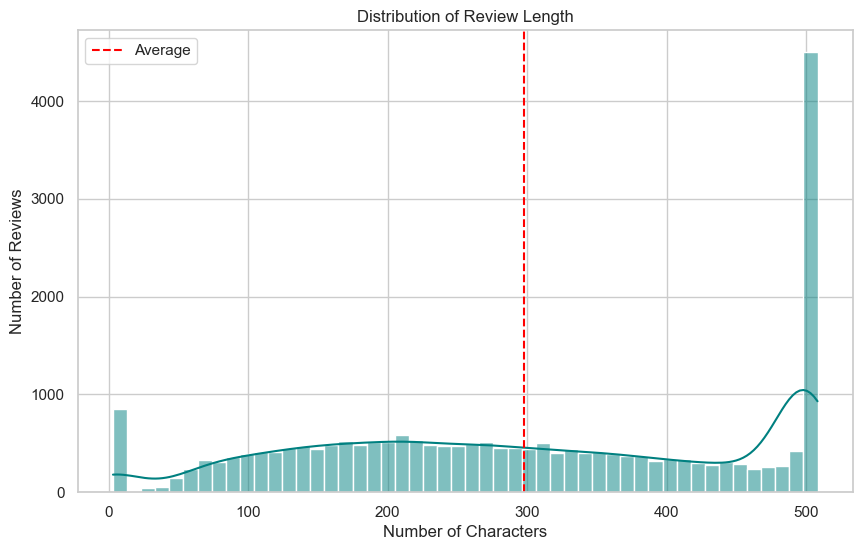

In [10]:
# Convert to string first, then calculate length
df_eda['Review_Length'] = df_eda['Review Text'].astype(str).apply(len)

plt.figure(figsize=(10, 6))
sns.histplot(df_eda['Review_Length'], bins=50, kde=True, color='teal')

plt.title('Distribution of Review Length')
plt.xlabel('Number of Characters')
plt.ylabel('Number of Reviews')

plt.axvline(df_eda['Review_Length'].mean(), color='red', linestyle='--', label='Average')
plt.legend()

plt.show()

The histogram shows that most customers provide detailed feedback. The frequency distribution confirms we have enough text data in most reviews to effectively train the sentiment classification model.

#### Correlation Heatmap

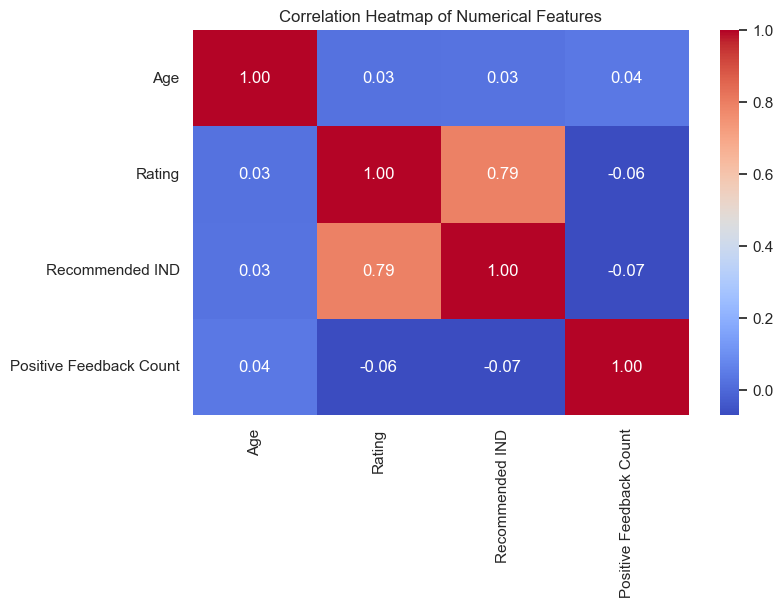

In [11]:
# Correlation Heatmap
plt.figure(figsize=(8, 5))
numeric_cols = ['Age', 'Rating', 'Recommended IND', 'Positive Feedback Count']
sns.heatmap(df_eda[numeric_cols].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap of Numerical Features')
plt.show()

The heatmap shows a strong positive correlation between Rating and Recommended IND, since highly rated products are usually recommended. Other numerical features like Age and Positive Feedback Count show low correlation with each other, It indicates that multicollinearity is not an issue for future models.

The Exploratory Data Analysis confirms the dataset contains sufficient quality and enough rows to proceed the model development. In the next milestone, I will focus on essential preprocessing, including handling missing values, removing outliers, and applying feature scaling to ensure optimal model performance.

### Data Preparation

Data cleaning, structuring, NaN handling and transforming raw data into a clean, machine learning format for analysis and modeling


#### NaN values handling

In [12]:
df_prp = df_eda.copy()
df_prp.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23486 entries, 0 to 23485
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   Clothing ID              23486 non-null  int64 
 1   Age                      23486 non-null  int64 
 2   Title                    19676 non-null  object
 3   Review Text              22641 non-null  object
 4   Rating                   23486 non-null  int64 
 5   Recommended IND          23486 non-null  int64 
 6   Positive Feedback Count  23486 non-null  int64 
 7   Division Name            23472 non-null  object
 8   Department Name          23472 non-null  object
 9   Class Name               23472 non-null  object
 10  Review_Length            23486 non-null  int64 
dtypes: int64(6), object(5)
memory usage: 2.0+ MB


My supervised leanring model is based on "Review Text", so it can not be NULL, heance I am removing the empty Review Text rows.

In [13]:
# Droping Review Text NaN rows
df_prp = df_prp.dropna(subset=['Review Text'])

I am replacing NaN in Title with "Unknown", and not dropping Title = NaN rows in order to keep "Review Text" rows which is important for my sentiment analysis.

Many customers do not pay attention to provide title or subject to the reviews.

In [14]:
# Replacing NaN in Title with "Unknown" string.
df_prp['Title'] = df_prp['Title'].fillna('Unknown')

"Division Name", "Department Name" and "Class Name" are not important for sentiment analysis. I am dropping them from dataframe instead of dropping NaN rows.

In [15]:
df_sa = df_prp.copy()

# Dropping department related columns for sentiment analysis.
df_sa = df_sa.drop(columns = ["Division Name", "Department Name", "Class Name"])

df_sa.info()

<class 'pandas.core.frame.DataFrame'>
Index: 22641 entries, 0 to 23485
Data columns (total 8 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   Clothing ID              22641 non-null  int64 
 1   Age                      22641 non-null  int64 
 2   Title                    22641 non-null  object
 3   Review Text              22641 non-null  object
 4   Rating                   22641 non-null  int64 
 5   Recommended IND          22641 non-null  int64 
 6   Positive Feedback Count  22641 non-null  int64 
 7   Review_Length            22641 non-null  int64 
dtypes: int64(6), object(2)
memory usage: 1.6+ MB


#### Outliers handling

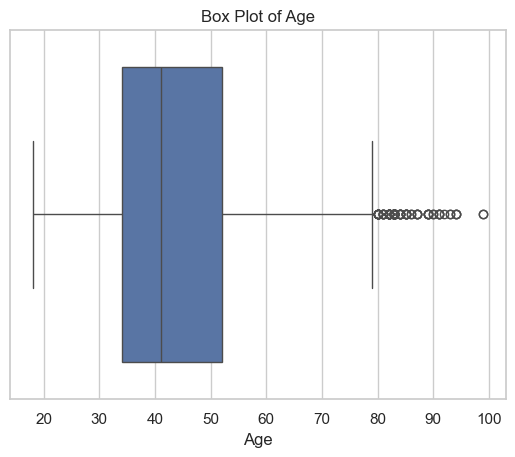

In [16]:
sns.boxplot(x=df_sa['Age'])
plt.title('Box Plot of Age')
plt.show()

In [17]:
Q1 = df_sa['Age'].quantile(0.25)
Q3 = df_sa['Age'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df_sa[(df_sa['Age'] < lower_bound) | (df_sa['Age'] > upper_bound)]

iqr_results = {'Q1': Q1, 'Q3': Q3, 'IQR': IQR, 
               'Lower Bound': lower_bound, 
               'Upper Bound': upper_bound,
               'Outlier Count': len(outliers) }

iqr_df = pd.DataFrame(iqr_results, index=['Age'])

print("-----Age IQR Outlier Summary Table-----:")
print(iqr_df)

-----Age IQR Outlier Summary Table-----:
       Q1    Q3   IQR  Lower Bound  Upper Bound  Outlier Count
Age  34.0  52.0  18.0          7.0         79.0            108


There are 108 outliers for Age. I am not dropping them. Since Age is not part of my sentiment analysis model. However I may handle them at later stage for other models where Age is a feature.

#### Preparing text data for sentiment analysis

In [18]:
# Load library
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem.porter import PorterStemmer


In [19]:
# loading set of stopwords for faster lookup
stop_words = set(stopwords.words("english"))

# creating stemmer
porter = PorterStemmer()

In [20]:
def clean_text(text: str) -> str:
    # Make lowercase and remove punctuation
    text = text.lower()
    text = text.translate(str.maketrans('', '', string.punctuation))

    word_token = word_tokenize(text)
    word_stop = [ word for word in word_token if word not in stop_words]
    wrod_stem = [porter.stem(word) for word in word_stop]

    # CountVectorizer needs a string, not a list.
    return " ".join(wrod_stem) #  return the "sentence" of stems.

In [21]:
# applying function to each element of review
df_sa['Review_Text_Stem'] = df_sa['Review Text'].apply(clean_text)

df_sa.head()

,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Review_Length,Review_Text_Stem
0,767,33,Unknown,Absolutely wonderful - silky and sexy and comfortable,4,1,0,53,absolut wonder silki sexi comfort
1,1080,34,Unknown,"Love this dress! it's sooo pretty. i happened to find it in a store, and i'm glad i did bc i n...",5,1,4,303,love dress sooo pretti happen find store im glad bc never would order onlin bc petit bought peti...
2,1077,60,Some major design flaws,I had such high hopes for this dress and really wanted it to work for me. i initially ordered th...,3,0,0,500,high hope dress realli want work initi order petit small usual size found outrag small small fac...
3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, flirty, and fabulous! every time i wear it, i get no...",5,1,0,124,love love love jumpsuit fun flirti fabul everi time wear get noth great compliment
4,847,47,Flattering shirt,This shirt is very flattering to all due to the adjustable front tie. it is the perfect length t...,5,1,6,192,shirt flatter due adjust front tie perfect length wear leg sleeveless pair well cardigan love shirt


#### Feature Extraction- Review Text as Bag of Words and TF-IDF

In [22]:
# load library
from sklearn.feature_extraction.text import CountVectorizer

In [23]:
cv = CountVectorizer()
bag_of_words = cv.fit_transform(df_sa['Review_Text_Stem'])

print(f"Bag of Words Shape: {bag_of_words.shape}")

Bag of Words Shape: (22641, 14814)


I have almost 14814 features - bag of words for my sentiment analysis.

I need to split the data into train and test before feature selection and do fit_tranform due to data leakage issue.

In [24]:
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer

In [25]:
from sklearn.feature_extraction.text import TfidfVectorizer

I need to apply fit_transform on only train data, and transform on test data.

Hence, I am splitting data into train and test here, so that all models have same test and train dataset.

In [26]:
# split train and test dataset
df_train, df_test = train_test_split(df_sa, test_size=0.2, 
                                     random_state=42, 
                                     stratify=df_sa['Recommended IND'])

# targets for Classification (Recommend vs Not)
y_train_class = df_train['Recommended IND']
y_test_class = df_test['Recommended IND']

# target for Regression (1-5 Stars)
y_train_reg = df_train['Rating']
y_test_reg = df_test['Rating']

**TfidfVectorizer()** creates both Term Frequency (TF) and Inverse Document Frequency (IDF).

TfidfVectorizer combines two steps:

CountVectorizer -> computes term frequency (TF)

TfidfTransformer -> computes inverse document frequency (IDF) and multiplies it with TF

In [27]:
tfidf = TfidfVectorizer(ngram_range=(1,2))

X_train_tfidf = tfidf.fit_transform(df_train['Review_Text_Stem'])
X_test_tfidf = tfidf.transform(df_test['Review_Text_Stem'])


In [28]:
print("Train set shape tf-idf:",X_train_tfidf.shape)
print("Test set shape tf-idf:",X_test_tfidf.shape)

Train set shape tf-idf: (18112, 219203)
Test set shape tf-idf: (4529, 219203)


#### Feature Selection- Chi2 Test

Naive Bayes model works with Non Negative values. I am using Chi-Square for feature selection so that it will work for both Naive Bayes and Logistics Regression model.

*A feature space of 219,203, I have an high-dimensional sparse matrix, and it is common when I am using ngram_range=(1,2).*

I am using Chi2 Test to select the most informative features.

In [29]:
from sklearn.feature_selection import SelectKBest, chi2


# Selecting the most informative features using Chi2 test
selector_chi2 = SelectKBest(chi2, k=25000)

# fit and tranform on train set
X_train_sel = selector_chi2.fit_transform(X_train_tfidf, y_train_class)

# transform on test set
X_test_sel = selector_chi2.transform(X_test_tfidf)

In [30]:
print("Train set shape Chi2:",X_train_sel.shape)
print("Test set shape Chi2:",X_test_sel.shape)

Train set shape Chi2: (18112, 25000)
Test set shape Chi2: (4529, 25000)


#### Features Reducing using Matrix Factorization

Using non-negative matrix factorization (NMF) to reduce the dimensionality of the feature matrix.

NMF is good here beacuse it keeps features positive which is important for Naive Bayes, and also reduced features work well with cluster and regression models.

In [31]:
from sklearn.decomposition import NMF

In [32]:
# Reducing features to 300 
nmf = NMF(
    n_components=300, 
    random_state=42, 
    init='nndsvda', 
    max_iter=1000,
)

X_train_nmf = nmf.fit_transform(X_train_sel)
X_test_nmf = nmf.transform(X_test_sel)

In [33]:
print("Train set shape nmf:",X_train_nmf.shape)
print("Test set shape nmf:",X_test_nmf.shape)

Train set shape nmf: (18112, 300)
Test set shape nmf: (4529, 300)


### Model Building and Evaluation

Selecting algorithms for sentiment classification and rating regression model, training them on data to identify patterns and evaluating model accuracy

### Logistic Regression- Classification

In our review text analysis, I am developing Logistic Regression model to predict the target class "Recommended IND".


In [34]:
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import classification_report, accuracy_score
from sklearn.metrics import roc_curve, auc

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [35]:
y_train_class.value_counts(normalize=True)

Recommended IND
1    0.818849
0    0.181151
Name: proportion, dtype: float64

Target class "Recommended IND" is imbalanced here.

In [36]:
# Deifning Logistic Regression model
logit_model = LogisticRegression(max_iter=1000, random_state=42,
                                 class_weight='balanced')

# Model training and prediction 
logit_model.fit(X_train_sel, y_train_class)
y_pred_lr_balanced = logit_model.predict(X_test_sel)


In [37]:
print("Logistic Regression with CLASS_WEIGHT='balanced':")
accuracy_score_lr = accuracy_score(y_test_class, y_pred_lr_balanced)
print(f"Accuracy: {accuracy_score_lr:.2%}")

cls_report_lr_wgt = classification_report(y_test_class, y_pred_lr_balanced)
print(cls_report_lr_wgt)

Logistic Regression with CLASS_WEIGHT='balanced':
Accuracy: 85.60%
              precision    recall  f1-score   support

           0       0.57      0.82      0.67       820
           1       0.96      0.86      0.91      3709

    accuracy                           0.86      4529
   macro avg       0.76      0.84      0.79      4529
weighted avg       0.89      0.86      0.87      4529



Logistic Regression with balanced class weights achieved a accuracy of 85.60%. It's Class 0 Recall (0.82), ensuring that the vast majority of non-recommendations are identified for manual review. 

### Random Forest Classification

I am trying a model ensemble approach using Random Forest classifier to improve the accuracy and recall of class Recommended IND = '0'.

I am also using GridSearchCV to select best model hyperparameters.

In [38]:
from sklearn.ensemble import RandomForestClassifier

from sklearn.model_selection import GridSearchCV

In [39]:
# Defining Random Forest Classifier model
rf_model = RandomForestClassifier(random_state=42, 
                                class_weight='balanced',
                                n_jobs = -1)

# Search Space Random Forest
rf_param_grid = {
    'n_estimators': [100, 200, 300],  # Number of trees
    'max_depth': [15, 20, 30],     # How deep each tree goes
    'min_samples_split': [2, 5, 10]   # Minimum data points to make a split
}

# Creating grid search- Random Forest and 
rf_grid = GridSearchCV(rf_model, rf_param_grid, cv=5, scoring='accuracy', n_jobs=-1)


In [ ]:
# Fitting grid search- Random Forest
rf_grid.fit(X_train_sel, y_train_class);

In [ ]:
print(f"Model Ensemble Random Forest CLASS_WEIGHT='balanced':")
print(f"  Best Hyperparameters: {rf_grid.best_params_}")
print(f"  Random Forest CV Accuracy: {rf_grid.best_score_:.2%}")

# predicting test value- Random Forest
y_pred_rf = rf_grid.predict(X_test_sel)
cls_report_rf = classification_report(y_test_class, y_pred_rf)
print("\nRandom Forest classification report:\n", cls_report_rf)


Random Forest classifier has the higher accuracy 88% then Logistic Regression. Logistic Regression is significantly better at finding the unhappy customer's reveiws.

In retail, "Recommended No" is a high risk data point. Logistic Regression finds 82% of these people. Random Forest only finds 61%. Logistic Regression has f1-score = 0.67 for class = 0, 0.67 and f1-score = 0.91 for class = 1.   

**I am proposing to deploy the Balanced Logistic Regression as our primary 'Sentiment Analysis.' The Logistic Regression is significantly more sensitive to dissatisfaction.**


In [ ]:
# confusion matrix

conf_matrix_lr = confusion_matrix(y_test_class, y_pred_lr_balanced)

# create confusion matrix
conf_df = pd.DataFrame(conf_matrix_lr, index = logit_model.classes_, columns = logit_model.classes_)

# Decimal places and no scientific notation
pd.options.display.float_format = '{:.4f}'.format

print(f"Logistic Regression Accuracy: {accuracy_score_lr:.2%}")

# create heatmap
sns.heatmap(conf_df, annot = True, fmt = 'd', cbar = None, cmap = "Blues")
plt.title("Logistic Regression: Confusion Matrix")
plt.tight_layout()
plt.ylabel("True Class")
plt.xlabel("Predicted Class")
plt.show()


We are correctly identifying 676 out of 820 negative reviews. The model prioritizes Class 0 Recall (0.824) to ensure that the vast majority of customer dissatisfaction is identified during the initial processing phase. It helps the customer service and marketing departments provide better customer service.

In [ ]:
Random Forest has the highest "Accuracy," Logistic Regression is the superior business model here.

In [ ]:
# ROC Curve
y_lr_prob = logit_model.predict_proba(X_test_sel)[:,1] # Get probability for the positive class

# create true and false positive rates 
false_positive_rate, true_positive_rate, threshold = roc_curve(y_test_class, y_lr_prob )

roc_auc = auc(false_positive_rate, true_positive_rate)

plt.figure(figsize=(8, 6))
plt.plot(false_positive_rate, true_positive_rate, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], 'k--') # Diagonal line representing random guessing
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Logistics Regression- Receiver Operating Characteristic (ROC)')
plt.legend(loc="lower right")
plt.show()

# Add this line to see the result
print(f"The AUC Score is: {roc_auc:.4f}")

An AUC = 0.92 is good score, it shows that  model has a 92% probability of correctly distinguishing between a random positive and a random negative review.

### Random Forest Regressor - Regression

In dataset Rating is an ordinal categorical variable, I am implementing a Regression rather than classification. This allows the model to output continuous values like 3.5 or 4.5. It provides a more granular Sentiment Score. 

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor

I am combining the "Age" and "Positive Feedback Count", and "Recommended IND" in my non-negative matrix (NMF) factorization features to predict Rating.

In [ ]:
# Preparing features
scaler = StandardScaler()
num_cols = ['Age', 'Positive Feedback Count']
num_features_train = scaler.fit_transform(df_train[num_cols])
num_features_test = scaler.transform(df_test[num_cols])

# No scaling Recommended IND = 0/1 
rec_train = df_train['Recommended IND'].values.reshape(-1, 1)
rec_test = df_test['Recommended IND'].values.reshape(-1, 1)

# Combining NMF + Age + Recommended IND + Positive Feedback Count
X_train_cmb = np.hstack((X_train_nmf, num_features_train, rec_train))
X_test_cmb = np.hstack((X_test_nmf, num_features_test, rec_test))

In [ ]:
# Random Forest Regressor
rf_reg = RandomForestRegressor(random_state=42, n_jobs=-1)

# Fitting model
rf_reg.fit(X_train_cmb, y_train_reg);

In [ ]:
# predicting rating
y_pred_rfr = rf_reg.predict(X_test_cmb)

# R2 score
r2_score_rf = r2_score(y_test_reg, y_pred_rfr)

print("Random Forest Regressor:")
print(f"Random Forest R2 Score: {r2_score_rf:.4f}")

### Light Gradient Boosting Model- Regression

I try to improve the score using Gradient Boosting tree-based model. It is computationally optimized.

In [ ]:
import lightgbm as lgb

In [ ]:
# lightbgm parameters
lgb_params = {
    'n_estimators': 500,  # enough tries to learn 200+ features
    'learning_rate': 0.05, # model learning from its mistakes
    'max_depth': 10,      
    'random_state': 42,
    'n_jobs': -1,
    'verbosity': -1       
}

# lightbgm model
lgb_reg = lgb.LGBMRegressor(**lgb_params)

# lightbgm model fitting
lgb_reg.fit(X_train_cmb, y_train_reg)


In [ ]:
# 300 NMF topics + Age + Positive Feedback Count + Recommended IND
feature_names = [f'NMF_Topic_{i}' for i in range(300)] + ['Age', 'Positive Feedback Count', 'Recommended IND']

# Converting test array into a DataFrame before predicting
X_test_df = pd.DataFrame(X_test_cmb, columns=feature_names)

# lgb predicting
y_pred_lgb = lgb_reg.predict(X_test_df)

r2_score_lgb = r2_score(y_test_reg, y_pred_lgb)
print("Light Gradient Boosted Regressor:")
print(f"LightGBM R-squared: {r2_score_lgb:4f}")

Light GBM has R2 score = 0.69 higher than Random Forest R2 Score = 0.67.

I am going to pick Light GBM model to predict Ratings for customer reveiws.

In [ ]:
# LGBM Mean Squared Error
mse_lgb = mean_squared_error(y_test_reg, y_pred_lgb)

# LGBM Root Mean Squared Error
rmse_lgb = np.sqrt(mse_lgb)

# LGBM Mean Absolute Error
mae_lgb = mean_absolute_error(y_test_reg, y_pred_lgb)

In [ ]:
print("Light Gradient Boosted Regressor:")
print(f"LightGBM R-squared: {r2_score_lgb:.4f}")
print(f"LightGBM RMSE: {rmse_lgb:.4f}")
print(f"LightGBM MAE: {mae_lgb:.4f}")

I am going to check what important features are affecting product rating.

In [ ]:
# Important features
importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': lgb_reg.feature_importances_
}).sort_values(by='Importance', ascending=False)

# Plotting top 10
plt.figure(figsize=(10, 4))
sns.barplot(x='Importance', y='Feature', data=importance.head(10))
plt.title('Top 10 Features of Product Ratings (LightGBM)')
plt.show()

In [ ]:
# nmf is  NMF model and tfidf is  tfidf_vectorizer
words = tfidf.get_feature_names_out()

for topic_id in [250, 52]:
    # Gettin the weights for this specific topic from the H matrix
    topic_weights = nmf.components_[topic_id]
    
    # Getting indices of the top 10 weights
    top_word_indices = topic_weights.argsort()[:-11:-1]
    
    # Mapping indices to actual words 
    top_words = [words[i] for i in top_word_indices]
    
    print(f"Topic {topic_id}: ")
    print(f"Top Words: {', '.join(top_words)}\n")

I can see that Age, Recommend IND, Positive Feeback Count and words in Topic 250 and 52 are top contributor to have good rating.

**Model Selection:**

We will use **Logistic Regression for customer review text analysis**. It has accuracy = 85.60%, recall = 0.82, and Precision = 0.57 for negative reviews, label = 0. The model is very good at identifying positive reviews and reasonably strong at finding negative reviews.

The **Light Gradient Boosted model is for predicting customer ratings**. R2 = 0.69 explains variance in Rating. 
MAE = 0.46; on average, our prediction is off by about 0.46 rating points, which is quite good given that our Rating is a numeric ordinal categorical value. Age, Recommend IND, Positive Feedback Count, and the number of words in Topics 250 and 52 are the top contributors to a good Rating.

By combining Logistic Regression 86% accuracy with our 0.69 R-squared LightGBM, we are no longer guessing if a customer is happy. We are measuring the exact intensity of their reviews and sentiments. Binary Classification and Continuous Regression together resolves the gap between in customer review and rating feedback. There is a chance when review is positive and rating is average.
